# 시계열 요약본

## 1. 시계열 데이터란?

### 1-1. 시계열 데이터의 정의
- 시간의 흐름에 따라 일정한 간격, 순서대로 관측·기록된 데이터 (예: 주가, 기온, 매출)

$$
Y_1, Y_2, \dots, Y_t, \dots, Y_T
$$

- 조건: 시간 순서가 의미를 가짐(순서를 섞으면 의미가 사라짐), 관측 간격(주기)이 일정함

| 구분 | 횡단면 데이터 | 시계열 데이터 |
|---|---|---|
| 관점 | 한 시점에 여러 대상을 관찰 | 한 대상을 여러 시점에 걸쳐 관찰 |
| 행 순서를 섞으면? | 아무 문제 없음 | 의미가 사라짐 |

- 단변량 시계열: 하나의 변수만 관측, 자기 자신의 과거 값만으로 예측 (예: 삼성전자 일별 종가)
- 다변량 시계열: 여러 변수를 동시에 관측, 다른 변수들의 영향까지 고려 (예: 판매량 ← 기온 + 강수량 + 요일)
- 시계열 분석의 주 목표는 미래 데이터 예측이며, "과거의 패턴이 미래에도 어느정도 반복될 것"이라는 가정 위에서 진행


### 1-2. 시계열 데이터의 특징

| 특징 | 내용 |
|---|---|
| 시간의존성 | 현재 시점의 값이 과거 시점의 값에 영향을 받는 성질 (가까운 과거일수록 영향이 큼, 순서를 섞으면 안 됨) |
| 계절성 | 일정한 주기(일, 주, 월, 년)로 비슷한 패턴이 반복되는 성질 |
| 추세 | 장기적으로 증가하거나 감소하는 방향성 |
| 자기상관성 | 현재 값과 과거 값이 얼마나 비슷하게 움직이는지 나타내는 정도 (−1 ~ 1), 시차를 바꿔가며 계산하면 반복주기를 찾을 수 있음 |

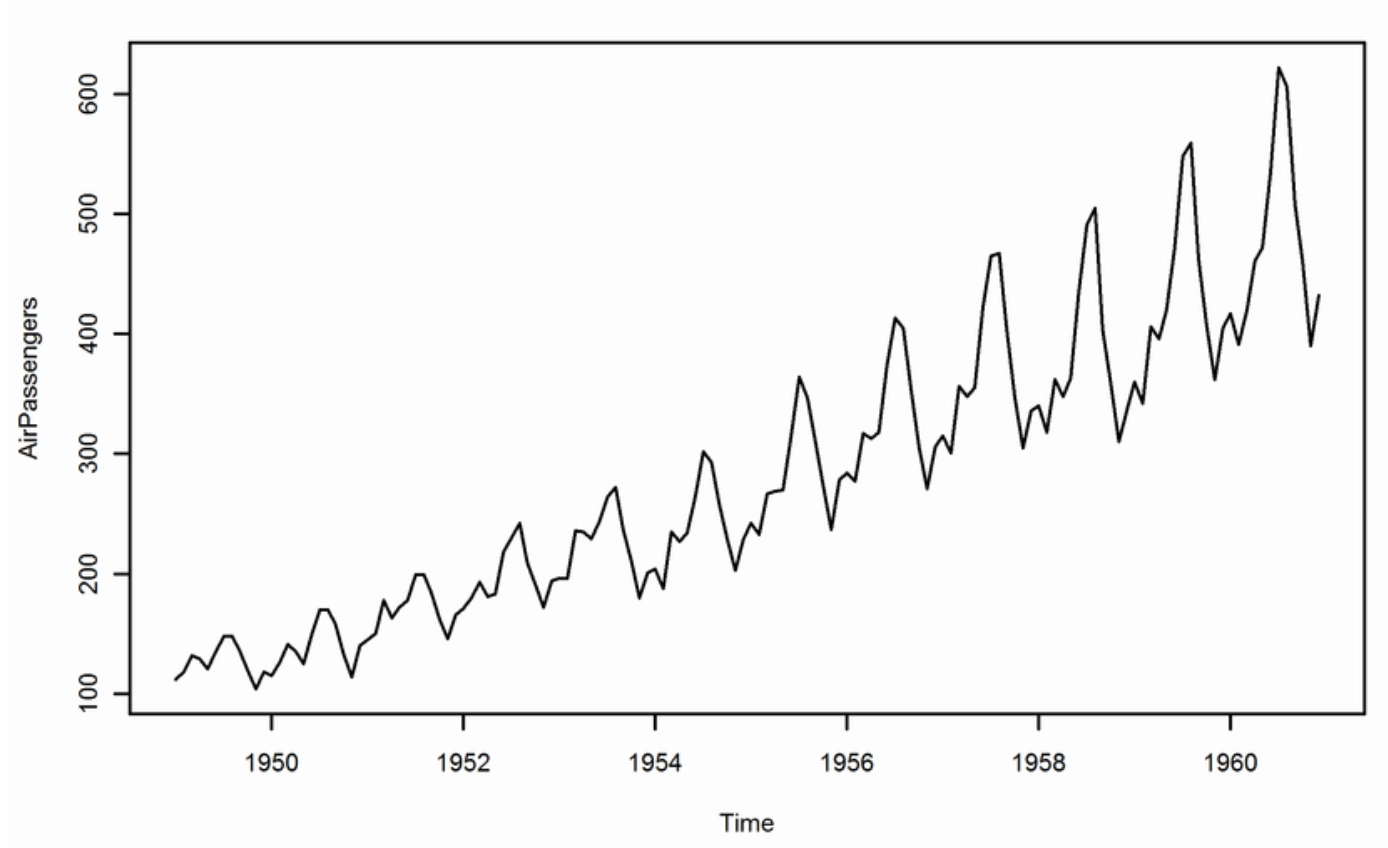

> 자기상관이 있으면 데이터가 독립적이라는 회귀분석의 가정이 깨짐 → 시계열 전용 모델을 쓰거나, 추세·계절성을 걷어내는 사전처리 후 분석해야 함

### 1-3. 시계열 데이터의 분석요인

| 요인 | 의미 | 주기 | 예시 |
|---|---|---|---|
| 추세 (T) | 시간 전반에 걸쳐 증가하거나 감소하는 경향성 | 없음 | 1인 가구 수 증가 |
| 계절 (S) | 1년 이내의 일정한 주기로 반복되는 패턴 | 고정 (1년 이내) | 여름 에어컨 판매 급증 |
| 순환 (C) | 계절성보다 길고 불규칙한 주기의 변동 | 불규칙 (수년) | 경기 호황·불황 |
| 불규칙 (I) | 위 요인을 모두 제거하고 남은 움직임 (잔차, 노이즈) | 없음 | 폭우로 매출 급감 |

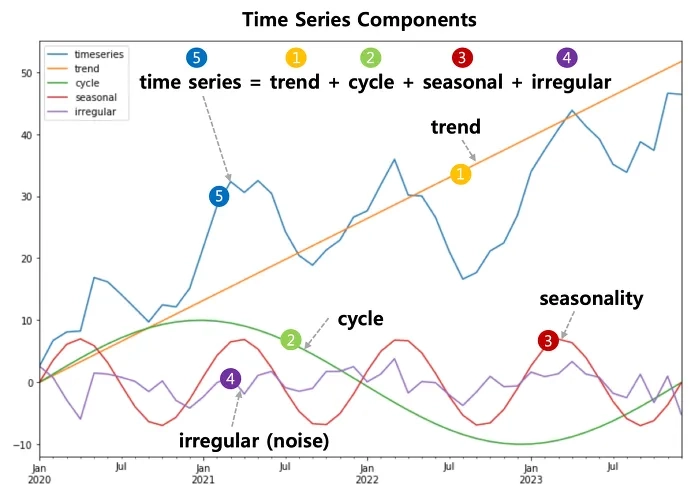

## 2. 시계열 데이터 전처리

### 2-1. 결측치/이상치 처리

**1) 결측치 처리**
- 시계열에서 행을 지우면 관측 간격이 깨지고, 전체 평균으로 채우면 시간 흐름이 무시됨

| 방법 | 설명 | 시계열에서의 한계 |
|---|---|---|
| 삭제 | 결측 시점 제거 | 관측 간격이 깨짐 |
| 단순 대치 | 평균, 중앙값 등으로 채움 | 추세와 계절성 무시 |
| 보간 | 앞뒤 관측값으로 사이의 값을 추정 | 앞뒤 값 필요 → 시계열에서 가장 많이 사용 |
| 이동평균 대치 | 주변 일정 구간의 평균으로 채움 | 구간 크기를 정해야 함 |
| 머신러닝 기법 | KNN, 회귀 모델 등으로 예측해서 채움 | 복잡하고 계산량이 많음 |

- 보간 예: 2일 110, 3일 ?, 4일 130 → 직선으로 이으면 3일 값은 120

**2) 이상치 탐지**
- 시계열의 이상치는 언제 나타났는지가 중요 (기온 35도 → 8월이면 정상, 1월이면 이상치) → 추세와 계절성을 고려해 판단

| 방법 | 원리 | 특징 |
|---|---|---|
| IQR | Q1−1.5×IQR 미만, Q3+1.5×IQR 초과 값을 이상치로 판단 | 간단, 추세·계절성이 강하면 부적합 |
| Z-score | $Z = (x - \mu)/\sigma$의 절댓값이 3보다 크면 이상치 | 간단, 정규분포 가정 (Rolling Z-score로 추세 영향 감소) |
| STL 분해 | 추세·계절을 제거한 잔차가 임곗값을 넘으면 이상치 | 계절성·추세가 뚜렷한 시계열에 적합 |
| CART | 예측값과 실제값의 오차가 큰 지점을 이상치로 판단 | 비선형 관계 포착, 과적합 위험 |
| 클러스터링 | 어느 군집에도 속하지 않는 데이터를 이상치로 판단 | 라벨 불필요, 하이퍼파라미터에 민감 |
| 오토인코더 | 정상 데이터로 학습 후 복원 오차가 큰 곳을 이상치로 판단 | 복잡한 패턴 가능, 많은 데이터·계산량 필요 |

> 처음에는 IQR, Z-score로 시작하고, 계절성이 뚜렷하면 STL, 데이터가 크고 복잡하면 모델 기반 방법을 고려

**3) 이상치 처리**
- 먼저 오류인지 실제 사건인지 확인한 뒤, 값을 비워서(NaN) 결측치로 바꾸고 보간으로 채우는 방식을 많이 사용

### 2-2. 평활화
- 시계열의 자잘한 오르내림(노이즈)을 줄여 큰 흐름을 드러내는 기술 → 주로 EDA에서 사용
- 이동평균: 연속된 N개의 데이터 평균을 한 칸씩 옮겨가며 계산하는 대표적인 평활화 방법

$$
MA_t = \frac{Y_t + Y_{t-1} + \cdots + Y_{t-N+1}}{N}
$$

- 예 (N=3): 100 → 130 → 110 → 140 → 120을 이동평균하면 113.3 → 126.7 → 123.3
- N이 작으면 변화에 빠르게 반응하지만 노이즈가 남고 N이 크면 매끄럽지만 변화에 늦게 반응하므로 보고 싶은 흐름의 길이에 맞게 정해야 함
- 유형: 단순(SMA), 가중(WMA), 지수(EMA) 이동평균

### 2-3. 요소분해
- 여러 요인이 섞인 시계열을 각각의 요인으로 다시 나누는 과정 (순환은 따로 찾기 어려워 보통 추세에 포함 → T, S, R 세 가지로 분해)

**1) 분해 모형: 가법 모형 / 승법 모형**

| 구분 | 가법 모형 | 승법 모형 |
|---|---|---|
| 수식 | $Y_t = T_t + S_t + R_t$ | $Y_t = T_t \times S_t \times R_t$ |
| 계절 변동 크기 | 추세와 상관없이 일정 | 추세에 비례해서 커짐 |
| 그래프 모양 | 물결 높이가 일정 | 물결 높이가 점점 커짐 |
| 예시 | 여름마다 항상 50잔 더 팔림 | 여름마다 항상 20% 더 팔림 |

**2) 분해 방법: seasonal_decompose / STL**

| 구분 | Seasonal Decompose (MA 기반) | STL (LOESS 기반) |
|---|---|---|
| 원리 | 이동평균으로 추세를 먼저 뽑고, 나머지에서 계절과 잔차를 차례로 분리 | 각 지점마다 주변 데이터로 작은 회귀선(LOESS)을 그려 추세와 계절을 추정 |
| 과정 | 추세 추출 → 추세 제거 → 계절성 추정(같은 계절 값들의 평균) → 잔차 산출 | Inner Loop(추세와 계절을 번갈아 추정) + Outer Loop(잔차가 큰 시점에 작은 가중치) |
| 특징 | 단순, 전통적 | 시간에 따라 바뀌는 패턴도 잘 잡고, 이상치에 강건(robust)함 |

## 3. 정상성 판단

### 3-1. 정상성의 정의 / 강한 정상성과 약한 정상성
- 정상성: 시계열의 평균, 분산, 자기상관 구조가 시간에 따라 변하지 않는 성질
- 시계열 예측의 기본 가정("과거의 패턴이 미래에도 반복")이 성립하기 위한 조건

| 구분 | 강한 정상성 | 약한 정상성 |
|---|---|---|
| 개념 | 확률분포 자체가 시간에 따라 전혀 변하지 않음 | 평균, 분산, 자기공분산만 변하지 않으면 됨 |
| 조건 | 시점을 h만큼 옮겨도 결합분포가 완전히 같음 | ① 평균 일정 ② 분산 일정 ③ 자기공분산이 시차(h)에만 의존 |
| 특징 | 현실에서 거의 찾아볼 수 없음 | 현실 데이터에 적용 가능, AR·MA·ARIMA가 가정하는 정상성 |

### 3-2. 정상성의 판단: 시각 / 통계

**1) 시각적 판단**

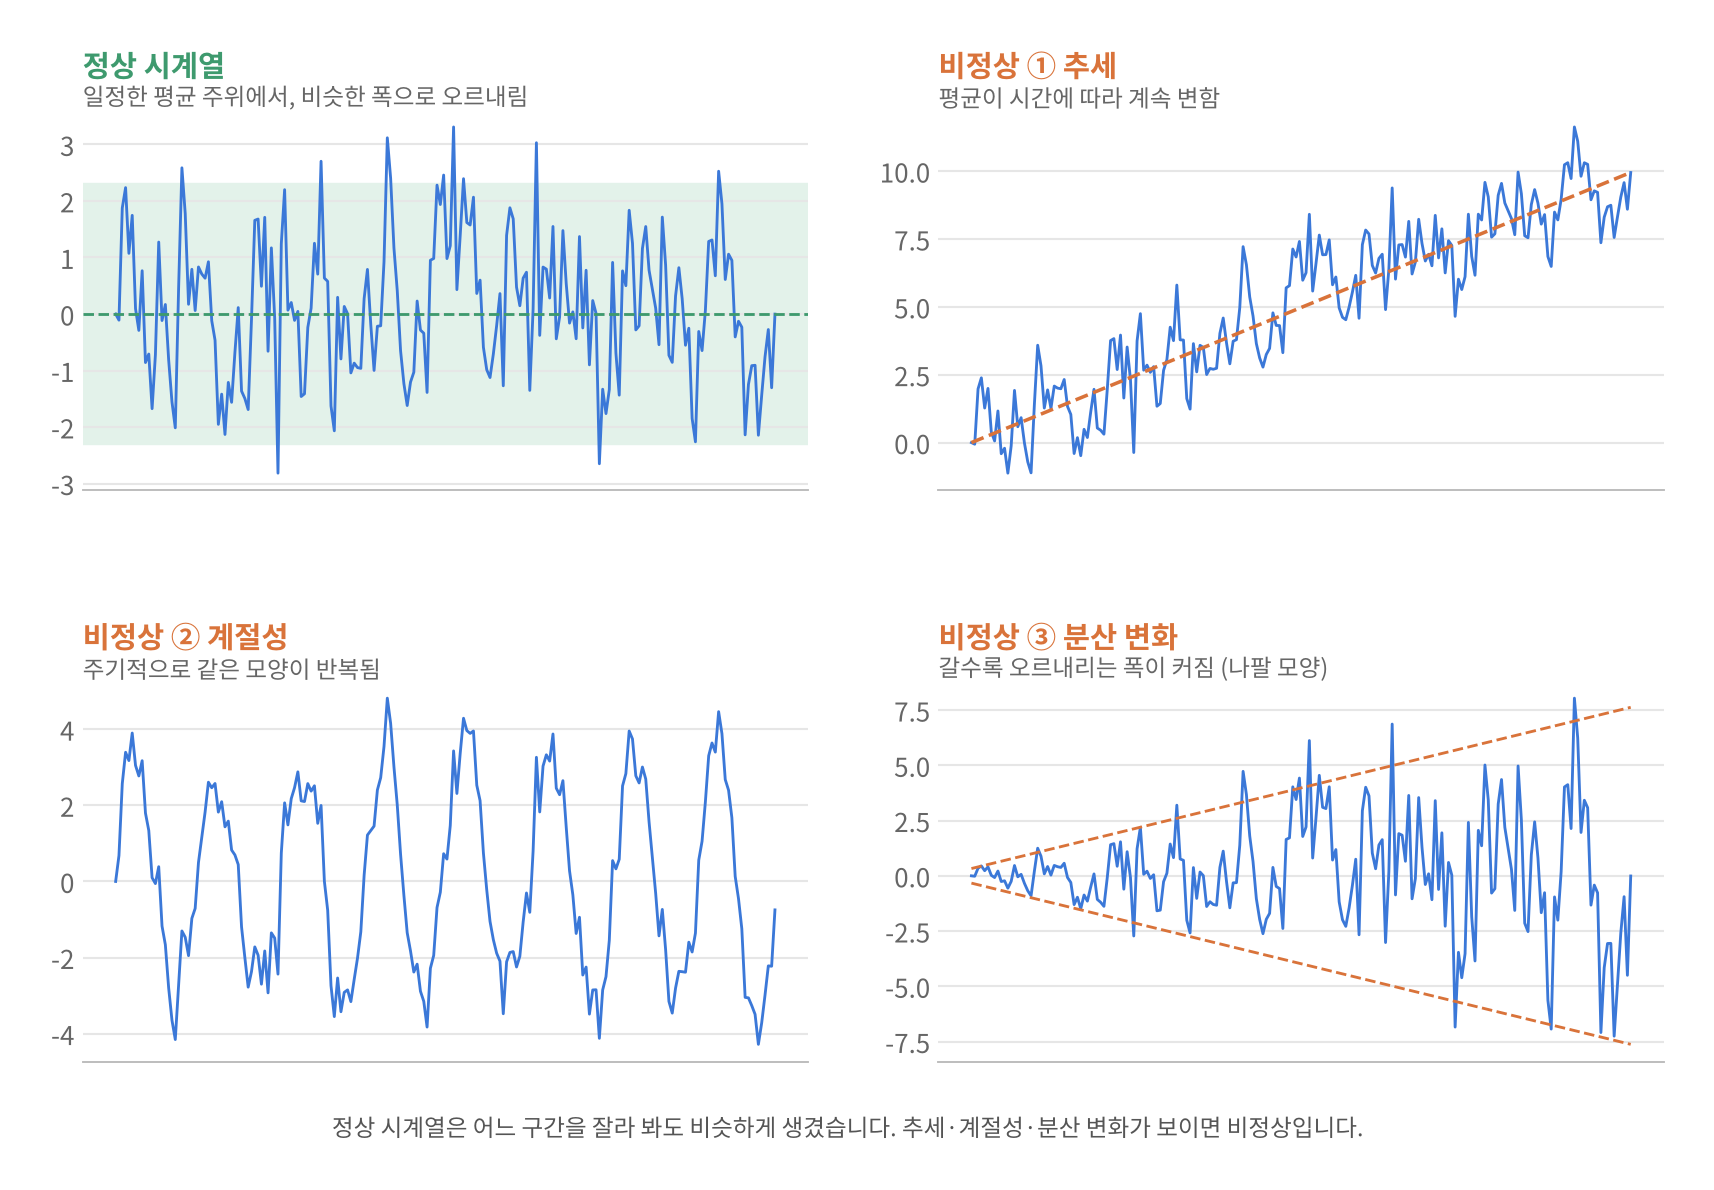

- 정상: 일정한 평균을 중심으로 비슷한 폭으로 오르내리고, 벗어나도 다시 평균으로 돌아옴
- 비정상: 추세(평균이 변함), 계절성(주기적 반복), 분산 변화(폭이 커지거나 작아짐)

**2) 통계적 검정: 단위근**
- 단위근: 과거 충격이 사라지지 않고 영구적으로 누적되는 특성 → 단위근이 있으면 비정상
- $Y_t = \phi Y_{t-1} + \varepsilon_t$에서 φ = 0.5이면 충격이 10 → 5 → 2.5로 사라지지만(정상), φ = 1이면 10 → 10 → 10으로 계속 남음(비정상)

| 구분 | ADF 검정 | KPSS 검정 |
|---|---|---|
| 귀무가설 (H₀) | 단위근이 있다 (비정상) | 시계열이 정상이다 |
| p-value < 0.05이면 | 귀무가설 기각 → 정상 | 귀무가설 기각 → 비정상 |

| ADF | KPSS | 진단 | 다음 액션 |
|---|---|---|---|
| 정상 | 정상 | 정상 시계열 | 바로 모델링 |
| 비정상 | 비정상 | 비정상 시계열 | 차분 후 재검정 |
| 비정상 | 정상 | 추세 정상 시계열 | 추세 제거 후 재검정 |
| 정상 | 비정상 | 차분 정상 시계열 | 차분 후 재검정 |

> 두 검정은 귀무가설이 반대라 서로 보완 (실무에서는 함께 사용)

### 3-3. 정상성 확보 방법

| 원인 | 방법 | 내용 |
|---|---|---|
| 추세 | 차분 $\Delta Y_t = Y_t - Y_{t-1}$ | 값 자체 대신 "얼마나 변했나"를 봄 → 추세와 단위근이 사라짐 (보통 2차까지만, 예측 후 역차분 필요) |
| 계절성 | 계절 차분 $\Delta_m Y_t = Y_t - Y_{t-m}$ | 한 주기 전 값을 뺌 ("작년 같은 때와 비교") → 계절 효과 상쇄 |
| 분산 변화 | 로그변환 | 큰 값은 많이, 작은 값은 조금 줄여 변동 폭을 정리 (0이나 음수에는 사용 불가) |

> 시계열 분석은 '정상성 확보 → 패턴 파악 → 적절한 모델링'의 순환적 과정

## 4. 단변량 시계열 분석

### 4-1. 안정적 시계열 분석
- 정상 시계열, 즉 돌아갈 "평소"가 있는 시계열을 분석

**1) AR / MA**

| 구분 | AR (자기 회귀) | MA (이동 평균) |
|---|---|---|
| 개념 | 오늘 값을 자기 자신의 과거 값으로 설명 | 오늘 값을 과거의 충격으로 설명 |
| 수식 (1차) | $y_t = c + \phi_1 y_{t-1} + \varepsilon_t$ | $y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1}$ |
| 비유 | 손님이 어제 손님 수를 보고 온다 | 손님이 어제 방송을 보고 온다 |
| 충격의 영향 | 끝없이 이어지며 서서히 옅어짐 (100 → 80 → 64 → 51) | 정해진 날수 뒤에 끊김 (100 → 80 → 0) |

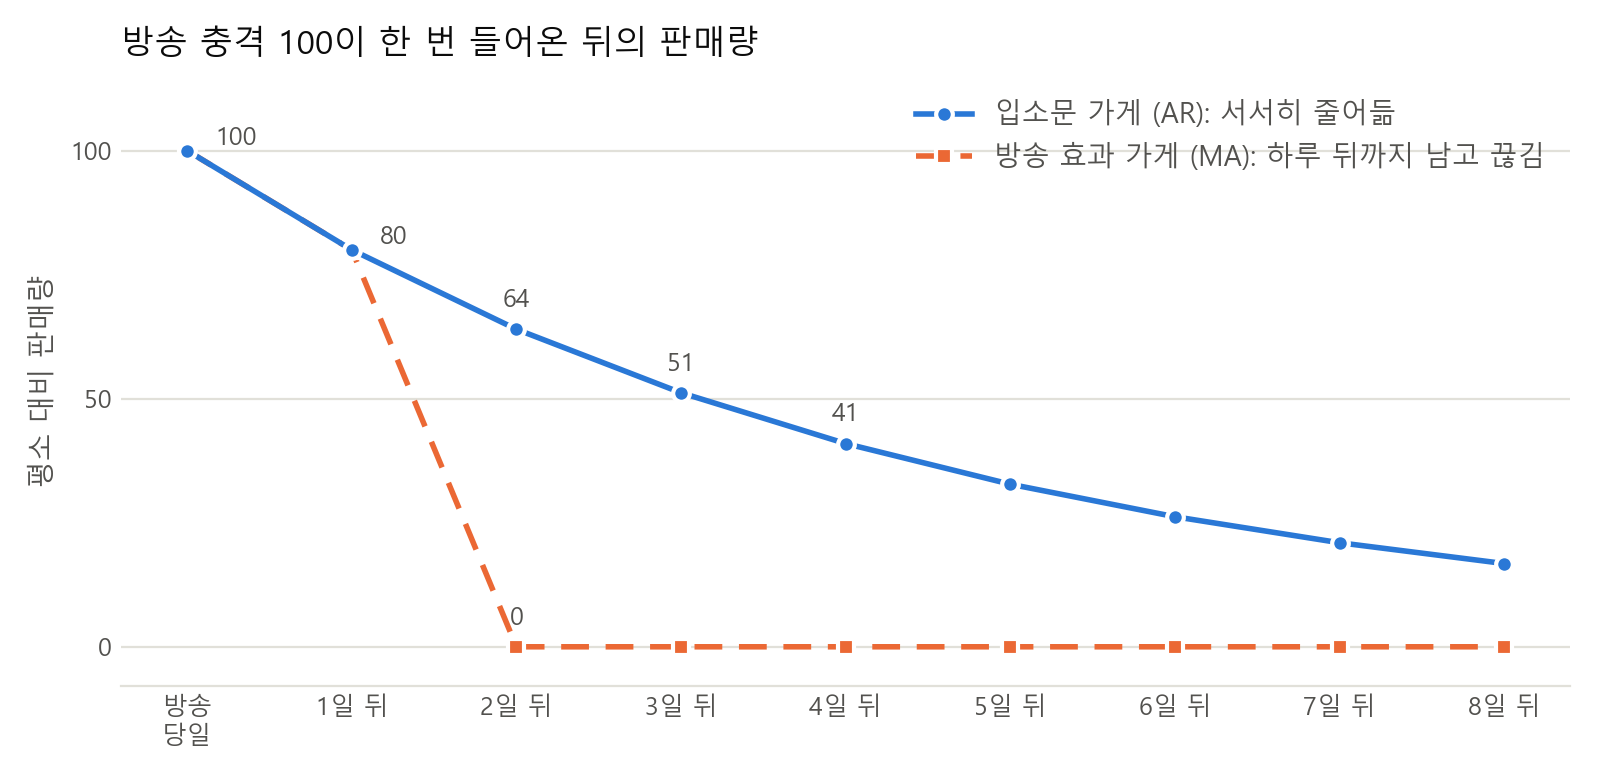

**2) AR, MA의 전제조건**

| | 정상성 | 가역성 |
|---|---|---|
| 뜻 | 충격을 받아도 시간이 지나면 평소로 돌아온다 | 판매량 기록으로 지난 충격을 거꾸로 계산해 낼 수 있다 |
| AR | 계수 조건 필요 (AR(1): $\lvert \phi_1 \rvert < 1$) | 항상 만족 |
| MA | 항상 만족 | 계수 조건 필요 (MA(1): $\lvert \theta_1 \rvert < 1$) |

- 모델의 정상성은 추정한 계수로 확인하는 것이므로 데이터를 보는 단위근 검정으로 대신할 수 없음

**3) ARMA**
- AR과 MA를 합친 모형 → 오늘 값이 과거 값과 과거 충격 양쪽의 영향을 받음

$$
y_t = c + \phi_1 y_{t-1} + \cdots + \phi_p y_{t-p} + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \cdots + \theta_q \varepsilon_{t-q}
$$

- AR만 쓸 때보다 더 적은 계수로 설명 가능, AR 부분은 정상성, MA 부분은 가역성 조건을 만족해야 함

**4) 차수 결정 방법: 자기 상관 함수 (ACF, PACF)**
- ACF: 오늘 값과 k시점 전 값의 상관 (중간 시점을 거쳐 온 영향까지 포함) → MA의 q 결정
- PACF: 중간 시점의 영향을 빼고 오늘 값과 k시점 전 값의 직접적인 상관 → AR의 p 결정

| ACF | PACF | 모델 |
|---|---|---|
| 천천히 감소 | p+1 시점부터 0에 근접 | AR(p) |
| q+1 시점부터 0에 근접 | 천천히 감소 | MA(q) |
| q+1 시점부터 0에 근접 | p+1 시점부터 0에 근접 | ARMA(p, q) |

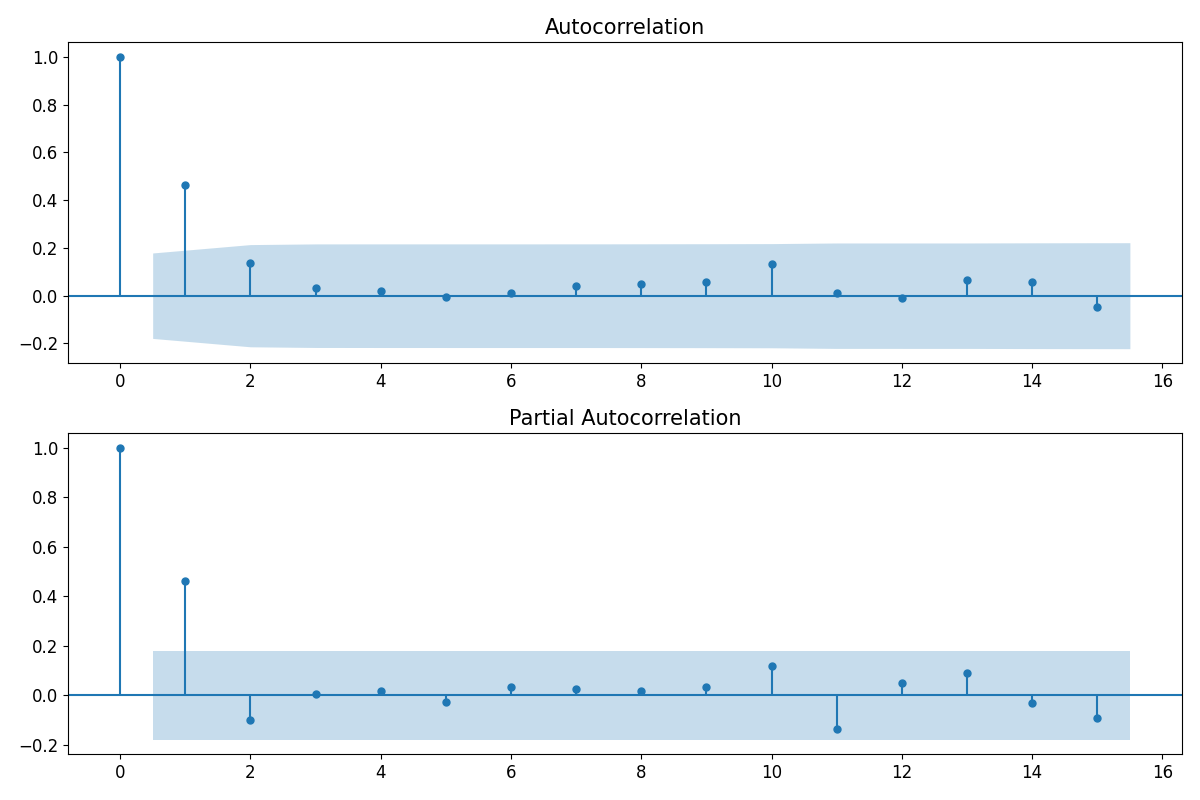

### 4-2. 불안정 시계열 분석
- 평소가 없는(비정상) 시계열 → 모형을 고치는 것이 아니라 차분으로 데이터를 모형이 다룰 수 있는 숫자로 바꿔 줌

**1) ARIMA(p, d, q)**
- ARMA에 차분(d)을 더한 모형 (p: AR 차수, d: 차분 횟수, q: MA 차수)
- 흐름: ① 차분해서 증감으로 바꿈 → ② 증감을 ARMA로 예측 → ③ 예측한 증감을 어제 값에 더해 되돌림
   - 예: 판매량 100, 103, 104, 108, 110 → 증감 평균 2.5 → 6일 예측 110 + 2.5 = 112.5
- 특수한 경우: 랜덤워크(상수 없는 ARIMA(0,1,0), 내일 값의 최선의 예측은 오늘 값), 표류를 포함하는 랜덤워크(상수 있는 ARIMA(0,1,0), 떠돌면서도 한 방향으로 흐름)

**2) SARIMA(p, d, q)(P, D, Q)ₘ**
- ARIMA에 계절 차분(D), 계절 AR(P), 계절 MA(Q)를 더한 모형 (m: 계절 주기, 월별 12)
- ARIMA가 "지난달 대비" 증감을 본다면, SARIMA는 "작년 같은 달 대비" 증감까지 봄
   - 예: 작년 12월 900, 올해 작년 대비 +50씩 증가 → 12월 예측 900 + 50 = 950
- 계절성 데이터는 ACF가 시차 12, 24, 36에서 다시 솟음 → 계절 차분을 먼저 수행
- 차수 결정: d, D는 ADF 검정으로 정상이 될 때까지 차분한 횟수 / p, q는 ACF·PACF로 범위를 정한 뒤 AIC, BIC로 그리드 서치

## 5. 다변량 시계열 분석

### 5-1. VAR (Vector Autoregression)
- AR을 변수 여러 개로 넓힌 모형 → 각 변수를 자기 자신의 과거와 다른 변수의 과거로 함께 예측

$$
X_t = a_{11} X_{t-1} + a_{12} Y_{t-1} + \varepsilon_{x,t}, \quad Y_t = a_{21} X_{t-1} + a_{22} Y_{t-1} + \varepsilon_{y,t}
$$

- $a_{11}, a_{22}$: 자기 자신에게서 오는 영향 / $a_{12}, a_{21}$: 서로에게 주는 영향
- 예: 판매량과 광고비 → 광고가 판매를 끌어올리고(+0.3), 잘 팔리면 광고를 줄임(−0.2)
- 적합한 경우: 변수들이 서로 영향을 주고받을 때, 변수 수가 적고 데이터가 충분할 때
- 부적합한 경우: 영향이 한 방향뿐일 때, 변수는 많은데 데이터가 적을 때
- 분석 방법: 충격 반응 함수(한 변수의 충격에 다른 변수가 어떻게 반응하는가), 예측오차 분산 분해(누구의 영향이 얼마나 큰가)